In [1]:
# logistical/os/plotting packages
import time
import os
from copy import deepcopy
# from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# mathematics packages
from random import sample
import random
import numpy as np
# import pandas as pd
# import math
from scipy.integrate import odeint

# define sources of randomness
#random.seed(42) #not needed but added to compare with other code templates
rng = np.random.default_rng()

# definition of the compartmental model used for simulations
# includes waning immunity and breakthrough infections
def compartment_rhs_multi_patch(x, t, disease_params, num_patches):
    # break state up into epidemiologically relevant categories
    #x is all subpopulations
    S1=x[0:num_patches]
    S2=x[num_patches:2*num_patches]
    V=x[2*num_patches:3*num_patches]
    E=x[3*num_patches:4*num_patches]
    I=x[4*num_patches:5*num_patches]
    R=x[5*num_patches:6*num_patches]
    N=S1+S2+V+E+I+R

    # omega: rate of losing vaccine immunity (V -> S2)
    # sigma: relative susceptibility/breakthrough factor for vaccinated individuals
    alpha, beta, mu, noo, c, gamma, delta, omega, sigma = disease_params
    
    # useful intermediate variable to improve efficiency
    force_of_infection = beta*(c*E+I)/(N+1e-9)  # when population hits zero, force of infection is zero

    dS1_dt = mu*N-alpha*S1-force_of_infection*S1 -noo*S1 
    dS2_dt = omega*V - force_of_infection*S2 - noo*S2
    dV_dt = alpha * S1 - sigma * force_of_infection * V - (noo+omega) * V           
    dE_dt = force_of_infection*(S1+S2+sigma*V)-(noo+gamma)*E
    dI_dt = gamma*E-(noo+delta)*I
    dR_dt = delta*I - noo*R
    dcum_cases_dt = gamma*E #keep tracking of the cumulative case count
    
    return np.concatenate([dS1_dt, dS2_dt, dV_dt, dE_dt, dI_dt, dR_dt, dcum_cases_dt])

def case_transport(x, conn_mat, num_patches):
    y = np.array(x, copy=True)

    # Keep the existing state-vector layout.
    S1 = y[:num_patches]
    S2 = y[num_patches:2*num_patches]
    V  = y[2*num_patches:3*num_patches]
    E  = y[3*num_patches:4*num_patches]
    R  = y[5*num_patches:6*num_patches]

    categories = np.floor(np.column_stack((S1, S2, V, E, R))).astype(np.int64)

    total_delta = np.zeros((num_patches, 5), dtype=np.int64)
    travel_ordering = np.random.permutation(num_patches)
    receive_ordering = np.random.permutation(num_patches)

    for i in travel_ordering:
        current_pool = categories[i].copy()

        for j in receive_ordering:
            sample_size = int(min(conn_mat[i, j], current_pool.sum()))
            travelers = rng.multivariate_hypergeometric(current_pool, nsample=sample_size)

            current_pool -= travelers
            total_delta[i] -= travelers
            total_delta[j] += travelers

    S1 += total_delta[:, 0]
    S2 += total_delta[:, 1]
    V  += total_delta[:, 2]
    E  += total_delta[:, 3]
    R  += total_delta[:, 4]

    return y

def day_step(x, conn_mat, disease_params, num_patches):
    x_dis = odeint(compartment_rhs_multi_patch, x, [0, 1], args=(disease_params, num_patches))[-1,:]
    detections = wastewater_detection(x_dis, np.ones(num_patches))
    return case_transport(x_dis, conn_mat, num_patches)

def wastewater_detection(x, detection_thresholds, exposure_sensitivity=0.5):
    num_patches = len(detection_thresholds)

    S1=x[0:num_patches]
    S2=x[num_patches:2*num_patches]
    V=x[2*num_patches:3*num_patches]
    E=x[3*num_patches:4*num_patches]
    I=x[4*num_patches:5*num_patches]
    R=x[5*num_patches:6*num_patches]
    N=S1+S2+V+E+I+R

    fraction_shedding = (exposure_sensitivity*E+I)/N
    return fraction_shedding >= detection_thresholds  # can set threshold to 1 or larger, equivalent to no surveillance

In [2]:
num_patches = 50
alpha = 0.0  # 0.86
beta = 1.06
gamma = 0.07
delta = 0.06
c = 0
mu = 0.00127
noo = 0.00127  # if noo is not equal to mu, then this R_0 is incorrect. Just for diagnostic purposes
omega = 0.001
sigma = 0.1
n_people = 3000
finish_sim = True

# calculate R_0
S_1_star = mu/(alpha+noo)
V_star = alpha/(omega+noo)*S_1_star
S_2_star = omega/noo*V_star
frac_adjusted = S_1_star + S_2_star + sigma*V_star
R_0 = beta*frac_adjusted*(c*(noo+delta)+gamma)/((noo+gamma)*(noo+delta))
print(f"Fixed population R_0: {R_0:.3f}")
print(f"S1: {mu/(alpha+noo)} S2: {mu*alpha*omega/(noo*(noo+omega)*(noo+alpha))} V: {mu*alpha/((noo+omega)*(noo+alpha))}")

Fixed population R_0: 16.992
S1: 1.0 S2: 0.0 V: 0.0


Text(0.5, 1.0, 'Adjacency matrix for subpopulations')

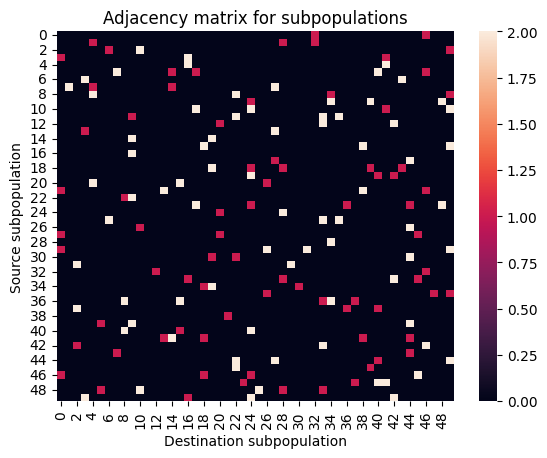

In [3]:
conn_mat = np.zeros((num_patches, num_patches))
for source in range(0, num_patches):
    for k in range(0,5):
        destination = np.random.randint(0, num_patches)
        if source != destination:
            conn_mat[source,destination] = np.random.randint(0,3)

ax = plt.axes()
sns.heatmap(conn_mat, ax=ax)
ax.set_xlabel("Destination subpopulation")
ax.set_ylabel("Source subpopulation")
ax.set_title("Adjacency matrix for subpopulations")

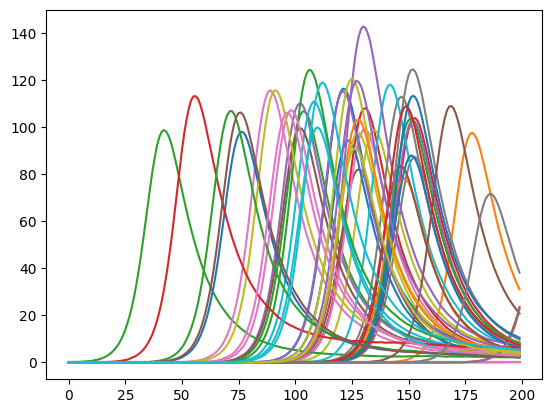

In [4]:
detection_sensitivity = 0.05*np.ones(num_patches)
disease_params = [alpha, beta, mu, noo, c, gamma, delta, omega, sigma]
ic = np.zeros(num_patches*7)
starting_patch = 12
initial_sick = 0.001
ic[0:num_patches] = n_people*mu/(alpha+noo)
ic[num_patches:2*num_patches] = n_people*mu*alpha*omega/(noo*(noo+omega)*(noo+alpha))
ic[2*num_patches:3*num_patches] = n_people*mu*alpha/((noo+omega)*(noo+alpha))
ic[starting_patch] -= initial_sick*n_people
ic[3*num_patches + starting_patch] = initial_sick*n_people
num_days = 200
results = np.zeros((num_days, num_patches*7))
results[0,:] = ic
first_detection_days = [None for i in range(0, num_patches)]

for i in range(1,num_days):
    results[i,:] = day_step(results[i-1,:], conn_mat, disease_params, num_patches)
    detections = wastewater_detection(results[i,:], detection_sensitivity)
    for k in range(0, num_patches):
        if first_detection_days[k] is None and detections[k]:
            first_detection_days[k] = i

for j in range(0,num_patches):
    plt.plot(list(range(0,num_days)), np.diff(results[:,j+6*num_patches],prepend=0))

Text(0.5, 0, 'Subpopulation')

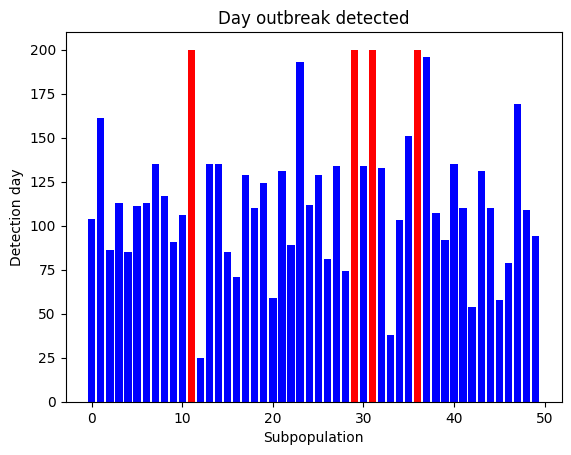

In [5]:
S1=results[:,0:num_patches]
S2=results[:,num_patches:2*num_patches]
V=results[:,2*num_patches:3*num_patches]
E=results[:,3*num_patches:4*num_patches]
I=results[:,4*num_patches:5*num_patches]
R=results[:,5*num_patches:6*num_patches]
populations=S1+S2+V+E+I+R
colors = ["blue" for i in range(0, num_patches)]

for i,x in enumerate(first_detection_days):
    if x is None:
        first_detection_days[i] = num_days
        colors[i] = "red"

plt.bar(list(range(0,num_patches)), first_detection_days, color=colors)
plt.title("Day outbreak detected")
plt.ylabel("Detection day")
plt.xlabel("Subpopulation")